# 04. MLP para Classificação — Baseline, `pos_weight` e Limiar de Decisão

**DCT1401 — Inteligência Artificial (UFRN, 2026.2)**
**Aluna:** Mariana dos Santos Batista Medeiros (Matrícula: 20230083988)

**Atividade 03 — Redes Neurais Artificiais com PyTorch: Classificação e Regressão**

Este notebook treina a rede neural de referência (*baseline*) para a classificação binária de `Cardiovascular_Disease` (0 = ausência; 1 = presença), usando o mesmo protocolo de dados do Notebook 03: as mesmas seis features, a mesma divisão em ajuste (12.800), validação (3.200) e teste (4.000) e o pré-processamento ajustado somente no subconjunto de ajuste.

Como a classe positiva representa cerca de 30,6% dos registros, o notebook também examina dois aspectos próprios da classificação desbalanceada:

1. o efeito do `pos_weight` na função de perda;
2. o efeito do limiar de decisão sobre Precision, Recall e F1-score.

Todas as análises usam o ajuste e a validação. **O conjunto de teste não participa do treinamento, da seleção nem da avaliação neste notebook.** O limiar definitivo é escolhido na validação, com o modelo final, no Notebook 06.

**Configuração do ambiente — Google Colab**

Esta etapa conecta o Google Colab ao Google Drive e configura os caminhos necessários para acessar o dataset original e os módulos Python do projeto.

A execução pressupõe que a pasta `projeto-cardiovascular-ia-03` esteja localizada em `Meu Drive`, conforme as instruções disponíveis no `README.md` da Atividade 03.

In [3]:
from google.colab import drive
from pathlib import Path
import importlib
import os
import sys

# 1. Conectar o Google Drive ao Colab
drive.mount("/content/drive")

# 2. Identificar a pasta principal do projeto
PROJETO = Path("/content/drive/MyDrive/projeto-cardiovascular-ia-03")

# 3. Verificar o dataset original e os módulos do projeto
ARQUIVO_RAW = PROJETO / "data/raw/cardiovascular_disease_prediction.csv"
assert ARQUIVO_RAW.is_file(), f"Dataset original não encontrado: {ARQUIVO_RAW}"

for modulo in ["__init__.py", "pipeline_data.py", "models.py", "train.py", "metrics.py"]:
    assert (PROJETO / "src" / modulo).is_file(), f"Módulo ausente em src/: {modulo}"

# 4. Definir a pasta notebooks como diretório de execução
os.chdir(PROJETO / "notebooks")

# 5. Permitir a importação dos módulos da pasta src
if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))

import src.pipeline_data as pipeline_data
import src.models as modelos_mlp
import src.metrics as metricas
import src.train as treino

# Recarrega os módulos, caso uma versão anterior esteja em memória
for modulo in (pipeline_data, modelos_mlp, metricas, treino):
    importlib.reload(modulo)

# 6. Pastas de saída
pasta_tabelas = PROJETO / "reports" / "tables"
pasta_figuras = PROJETO / "reports" / "figures"
pasta_curvas = PROJETO / "logs" / "curvas"
for pasta in (pasta_tabelas, pasta_figuras, pasta_curvas):
    pasta.mkdir(parents=True, exist_ok=True)

print("Projeto localizado em:", PROJETO)
print("Diretório de execução:", Path.cwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projeto localizado em: /content/drive/MyDrive/projeto-cardiovascular-ia-03
Diretório de execução: /content/drive/MyDrive/projeto-cardiovascular-ia-03/notebooks


### Registro do ambiente de execução

O registro completo do ambiente e as medições de eficiência são consolidados no Notebook 08.

In [4]:
import platform
import numpy as np
import pandas as pd
import psutil
import sklearn
import torch

DEVICE = "cpu"   # dispositivo fixo e declarado; CPU e GPU são comparadas no Notebook 08

ambiente = {
    "Sistema operacional": platform.platform(),
    "CPUs lógicas": os.cpu_count(),
    "Threads do PyTorch (torch.get_num_threads())": torch.get_num_threads(),
    "RAM total (GB)": round(psutil.virtual_memory().total / 1024**3, 2),
    "Python": platform.python_version(),
    "PyTorch": torch.__version__,
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "GPU disponível": torch.cuda.is_available(),
    "Dispositivo utilizado": DEVICE,
}
display(pd.Series(ambiente, name="Valor").to_frame())

,Valor
Sistema operacional,Linux-6.6.159+-x86_64-with-glibc2.39
CPUs lógicas,2
Threads do PyTorch (torch.get_num_threads()),1
RAM total (GB),12.67
Python,3.13.18
PyTorch,2.14.1+cpu
NumPy,2.4.6
Pandas,2.2.3
scikit-learn,1.6.1
GPU disponível,False


## 1. Dados e pré-processamento

O protocolo de dados é o mesmo do Notebook 03, onde ele é justificado em detalhe. A divisão é refeita a partir do CSV original e conferida automaticamente; o pré-processamento (codificação, imputação pela mediana e `StandardScaler` nas seis features) é ajustado somente nos 12.800 registros de ajuste e aplicado à validação.

Diferentemente da regressão, o alvo **não** é padronizado: ele é o rótulo 0/1, convertido para `float32` porque a `nn.BCEWithLogitsLoss` compara o logit com um valor real entre 0 e 1.

O `pos_weight` é calculado com as contagens do **ajuste**, nunca com a validação ou o teste:

$$\text{pos\_weight} = \frac{\text{número de negativos no ajuste}}{\text{número de positivos no ajuste}}$$

In [5]:
dados = pipeline_data.preparar_divisoes("../data/raw/cardiovascular_disease_prediction.csv")
print("Divisão conferida com as referências: OK\n")

dt = treino.preparar_dados_tarefa(dados, "classificacao")   # teste não incluído
assert set(dt["X"]) == {"ajuste", "validacao"}, "O teste não deve ser transformado neste notebook."
assert np.allclose(dt["X"]["ajuste"].mean(axis=0), 0, atol=1e-5)
assert dt["X"]["ajuste"].dtype == np.float32 and dt["y"]["ajuste"].dtype == np.float32

distribuicao = pd.DataFrame({
    "Registros": [len(dt["y_original"][c]) for c in ("ajuste", "validacao")],
    "Negativos (0)": [int((dt["y_original"][c] == 0).sum()) for c in ("ajuste", "validacao")],
    "Positivos (1)": [int((dt["y_original"][c] == 1).sum()) for c in ("ajuste", "validacao")],
}, index=["Ajuste", "Validação"])
distribuicao["% positivos"] = 100 * distribuicao["Positivos (1)"] / distribuicao["Registros"]
display(distribuicao.style.format({"% positivos": "{:.2f}"}))

POS_WEIGHT = dt["n_negativos_ajuste"] / dt["n_positivos_ajuste"]
PREVALENCIA_AJUSTE = dt["n_positivos_ajuste"] / (dt["n_positivos_ajuste"] + dt["n_negativos_ajuste"])
print(f"pos_weight = {dt['n_negativos_ajuste']} / {dt['n_positivos_ajuste']} = {POS_WEIGHT:.4f}")
print(f"Prevalência da classe positiva no ajuste: {PREVALENCIA_AJUSTE:.4f}")

Divisão conferida com as referências: OK



,Registros,Negativos (0),Positivos (1),% positivos
Ajuste,12800,8883,3917,30.60
Validação,3200,2221,979,30.59


pos_weight = 8883 / 3917 = 2.2678
Prevalência da classe positiva no ajuste: 0.3060


## 2. Arquitetura, camada de saída e função de perda

A rede é a mesma `MLP` do Notebook 03 (2 camadas ocultas de 32 neurônios, ReLU, 1.313 parâmetros). Muda apenas a interpretação da saída e a função de perda.

**Saída: 1 logit, sem ativação.** O problema é binário e cada registro pertence a exatamente uma das duas classes. Basta, portanto, um único número $z$ (logit), que a sigmoide converte na probabilidade da classe positiva:

$$\hat{p} = \sigma(z) = \frac{1}{1 + e^{-z}}$$

Não se trata de um problema multiclasse (que exigiria $C$ logits com *softmax* e `CrossEntropyLoss`), nem multi-rótulo (vários rótulos independentes por registro).

**Perda: `nn.BCEWithLogitsLoss`.** Ela aplica a sigmoide e a entropia cruzada binária em uma única operação:

$$L = -\frac{1}{N}\sum_{i=1}^{N}\Big[w_p\, y_i \log \sigma(z_i) + (1 - y_i)\log\big(1 - \sigma(z_i)\big)\Big]$$

com $w_p = 1$ sem `pos_weight`. Combinar as duas operações é numericamente mais estável do que aplicar `nn.Sigmoid` na rede e depois `nn.BCELoss`: para logits muito grandes ou muito pequenos, a sigmoide arredonda para 0 ou 1 e o logaritmo explode. Por isso a rede **não** tem sigmoide na saída; a sigmoide é aplicada apenas na inferência e no cálculo das curvas ROC e Precision–Recall.

**`pos_weight`.** Com $w_p > 1$, cada erro em um registro positivo pesa $w_p$ vezes mais na perda. O efeito esperado é deslocar as probabilidades previstas para cima, o que aumenta o Recall e reduz a Precision para um mesmo limiar. Esse efeito é medido na Seção 4.

In [6]:
rede_baseline = modelos_mlp.MLP(in_dim=6, out_dim=1, hidden=(32, 32), activation="ReLU")
print(rede_baseline)
n_parametros = modelos_mlp.contar_parametros(rede_baseline)
assert n_parametros == modelos_mlp.parametros_teoricos(d=6, n=32, L=2) == 1313
print(f"Parâmetros treináveis: {n_parametros}")

# Demonstração da estabilidade numérica: logit muito grande com rótulo 0 (erro grave)
logit = torch.tensor([[200.0]])
alvo = torch.tensor([[0.0]])
perda_separada = torch.nn.BCELoss()(torch.sigmoid(logit), alvo).item()
perda_combinada = torch.nn.BCEWithLogitsLoss()(logit, alvo).item()
print(f"\nLogit = 200 com rótulo 0 (valor correto da perda: 200):")
print(f"  Sigmoid + BCELoss:   {perda_separada:.1f}")
print(f"  BCEWithLogitsLoss:   {perda_combinada:.1f}")

MLP(
  (net): Sequential(
    (0): Linear(in_features=6, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Parâmetros treináveis: 1313

Logit = 200 com rótulo 0 (valor correto da perda: 200):
  Sigmoid + BCELoss:   100.0
  BCEWithLogitsLoss:   200.0


A demonstração mostra a diferença. Para logit 200 e rótulo 0, a perda correta é $-\log(1-\sigma(200)) \approx 200$. Com a sigmoide separada, $\sigma(200)$ é arredondada para exatamente 1 em `float32`, o termo vira $\log(0) = -\infty$, e o `BCELoss` corta o logaritmo em $-100$: a perda é registrada como 100, e o gradiente desse registro se perde. A versão combinada calcula a perda diretamente a partir do logit e devolve o valor correto.

## 3. Treinamento do baseline com cinco sementes

A configuração de referência é a mesma da regressão: 2 camadas ocultas de 32 neurônios, ReLU, Adam com taxa de aprendizado $10^{-3}$, *batch* de 32, até 200 épocas e *early stopping* com paciência de 20 épocas, monitorando a perda de validação. O baseline **não** usa `pos_weight`; o efeito do peso é avaliado separadamente na Seção 4.

O laço de treinamento, as sementes (0 a 4) e a convenção do desvio padrão (amostral, `ddof=1`) são os mesmos do Notebook 03.

**Métricas.** São calculadas no ajuste e na validação:

- **dependentes do limiar** (aqui, o limiar padrão de 0,5): Accuracy, Precision, Recall e F1-score;
- **independentes do limiar**, calculadas a partir das probabilidades: ROC-AUC, Average Precision (AP) e PR-AUC trapezoidal (área sob a curva Precision–Recall calculada pela regra do trapézio). A AP e a PR-AUC trapezoidal resumem a mesma curva com métodos de cálculo diferentes e podem ter valores diferentes; por isso, são reportadas separadamente;
- **de qualidade das probabilidades**: Log Loss e Brier Score, que medem se as probabilidades previstas são compatíveis com as frequências observadas (calibração).

**Métrica de comparação.** Para comparar configurações, o critério principal é a **Average Precision (AP) de validação**. Ela não depende do limiar e é adequada ao desbalanceamento: para um classificador que ordena os registros ao acaso, a AP fica próxima da prevalência da classe positiva (cerca de 0,31), e não de 0,5 como a ROC-AUC. A PR-AUC trapezoidal resume a mesma curva Precision–Recall por outro método e é reportada ao lado da AP como métrica complementar. O F1-score depende do limiar e só é usado depois que o limiar é escolhido na validação.

In [7]:
import json
import time
from scipy.special import expit

def config_json(config):
    return {k: list(v) if isinstance(v, tuple) else v for k, v in config.items()}

def treinar_sementes(config_extra, rotulo):
    # Treina uma configuração com as cinco sementes e guarda curvas e probabilidades.
    config = {**treino.CONFIG_BASELINE, **config_extra}
    registros, historicos, probabilidades = [], {}, {}
    for semente in treino.SEMENTES:
        modelo, resultado, registro = treino.executar_configuracao(dt, config_extra, semente, device=DEVICE)
        assert not registro["divergiu"], f"O treinamento divergiu na semente {semente}."
        registros.append(registro)
        historicos[semente] = resultado["hist"]
        probabilidades[semente] = {
            c: expit(treino.prever(modelo, dt["X"][c], DEVICE).astype(np.float64))
            for c in ("ajuste", "validacao")
        }
        with open(pasta_curvas / f"classificacao_{rotulo}_semente{semente}.json", "w", encoding="utf-8") as f:
            json.dump({"tarefa": "classificacao", "configuracao": rotulo, "semente": semente,
                       "config": config_json(config), "epoca_melhor": registro["epoca_melhor"],
                       "hist": resultado["hist"]}, f)
        m = registro["metricas_validacao"]
        print(f"[{rotulo}] semente {semente}: melhor época {registro['epoca_melhor']:3d} | "
              f"parada {registro['epocas_executadas']:3d} | AP val {m['Average_Precision']:.4f} | "
              f"ROC-AUC val {m['ROC-AUC']:.4f} | {registro['tempo_s']:.1f} s")
    tabela = treino.tabela_registros(registros)
    tabela["tempo_por_epoca_s"] = tabela["tempo_s"] / tabela["epocas_executadas"]
    return tabela, historicos, probabilidades

config_baseline = dict(treino.CONFIG_BASELINE)
display(pd.DataFrame({"Hiperparâmetro": list(config_baseline),
                      "Valor": [str(v) for v in config_baseline.values()]}))

inicio = time.perf_counter()
tabela_base, hist_base, prob_base = treinar_sementes({}, "baseline")
print(f"\nTempo total: {time.perf_counter() - inicio:.1f} s")

,Hiperparâmetro,Valor
0,hidden,"(32, 32)"
1,activation,ReLU
2,dropout,0.0
3,otimizador,Adam
4,lr,0.001
5,batch_size,32
6,weight_decay,0.0
7,n_epocas,200
8,paciencia,20
9,pos_weight,False


[baseline] semente 0: melhor época   7 | parada  27 | AP val 0.6866 | ROC-AUC val 0.8171 | 16.0 s
[baseline] semente 1: melhor época   8 | parada  28 | AP val 0.6877 | ROC-AUC val 0.8179 | 17.6 s
[baseline] semente 2: melhor época  23 | parada  43 | AP val 0.6848 | ROC-AUC val 0.8181 | 27.0 s
[baseline] semente 3: melhor época  16 | parada  36 | AP val 0.6875 | ROC-AUC val 0.8185 | 23.0 s
[baseline] semente 4: melhor época  13 | parada  33 | AP val 0.6881 | ROC-AUC val 0.8181 | 19.7 s

Tempo total: 116.7 s


In [8]:
METRICAS_CLF = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC",
                "Average_Precision", "Log_Loss", "Brier"]
formato = lambda v: f"{v:.4f}"

colunas_exibidas = (["semente", "epoca_melhor", "epocas_executadas", "tempo_s"]
                    + [f"{m}_validacao" for m in METRICAS_CLF])
print("BASELINE DE CLASSIFICAÇÃO — VALIDAÇÃO POR SEMENTE (limiar 0,5)")
display(tabela_base[colunas_exibidas].style.format(precision=4).hide(axis="index"))

colunas_resumo = ([f"{m}_{c}" for m in METRICAS_CLF for c in ("ajuste", "validacao")]
                  + ["epoca_melhor", "epocas_executadas", "tempo_s", "tempo_por_epoca_s"])
resumo_base = treino.resumir_sementes(tabela_base, colunas_resumo)
print("\nBASELINE DE CLASSIFICAÇÃO — MÉDIA E DESVIO ENTRE AS CINCO SEMENTES")
display(resumo_base.style.format(formato))

BASELINE DE CLASSIFICAÇÃO — VALIDAÇÃO POR SEMENTE (limiar 0,5)


semente,epoca_melhor,epocas_executadas,tempo_s,Accuracy_validacao,Precision_validacao,Recall_validacao,F1-score_validacao,ROC-AUC_validacao,PR-AUC_validacao,Average_Precision_validacao,Log_Loss_validacao,Brier_validacao
0,7,27,16.0110,0.7863,0.6913,0.5444,0.6091,0.8171,0.6863,0.6866,0.4639,0.1508
1,8,28,17.5582,0.7906,0.6924,0.5679,0.6240,0.8179,0.6874,0.6877,0.4623,0.1500
2,23,43,27.0342,0.7859,0.6856,0.5546,0.6132,0.8181,0.6845,0.6848,0.4633,0.1506
3,16,36,23.0425,0.7894,0.6899,0.5659,0.6218,0.8185,0.6872,0.6875,0.4622,0.1500
4,13,33,19.6767,0.7866,0.6968,0.5352,0.6054,0.8181,0.6878,0.6881,0.4632,0.1504



BASELINE DE CLASSIFICAÇÃO — MÉDIA E DESVIO ENTRE AS CINCO SEMENTES


,média,desvio (ddof=1),mínimo,máximo
Accuracy_ajuste,0.7945,0.0016,0.7924,0.7965
Accuracy_validacao,0.7878,0.0021,0.7859,0.7906
Precision_ajuste,0.7033,0.0071,0.6937,0.7128
Precision_validacao,0.6912,0.0041,0.6856,0.6968
Recall_ajuste,0.5688,0.0135,0.5494,0.5805
Recall_validacao,0.5536,0.0139,0.5352,0.5679
F1-score_ajuste,0.6288,0.0063,0.6205,0.6348
F1-score_validacao,0.6147,0.0080,0.6054,0.6240
ROC-AUC_ajuste,0.8208,0.0015,0.8194,0.8231
ROC-AUC_validacao,0.8179,0.0005,0.8171,0.8185


### 3.1 Referências ingênuas

Duas referências mostram o que as métricas significam neste problema desbalanceado:

- **Classe majoritária:** prevê sempre "ausência" (0). Não identifica nenhum positivo, mas acerta todos os negativos.
- **Prevalência constante:** atribui a todos os registros a mesma probabilidade, igual à proporção de positivos no ajuste. Não ordena os registros, então ROC-AUC = 0,5 e AP = prevalência; serve como referência para Log Loss e Brier.
- **Regressão logística:** modelo linear, ajustado nos mesmos dados padronizados do ajuste. Tem capacidade muito menor que a rede (7 parâmetros) e quase não consegue sobreajustar. Serve para duas leituras: se a rede supera um modelo linear (ou seja, se as não linearidades acrescentam informação) e qual é a diferença natural entre ajuste e validação para um modelo simples (Seção 8).

In [9]:
y_val = dt["y_original"]["validacao"]
n_val = len(y_val)

referencias = {}
# Classe majoritária: probabilidade 0 para todos -> limiar 0,5 prevê sempre 0
referencias["Classe majoritária (sempre 0)"] = metricas.calcular_metricas_classificacao(
    y_val, np.zeros(n_val))
# Prevalência constante: mesma probabilidade para todos
referencias["Prevalência constante"] = metricas.calcular_metricas_classificacao(
    y_val, np.full(n_val, PREVALENCIA_AJUSTE))

# Regressão logística: referência linear de baixa capacidade, ajustada só no ajuste
from sklearn.linear_model import LogisticRegression
logistica = LogisticRegression(max_iter=1000).fit(dt["X"]["ajuste"], dt["y_original"]["ajuste"])
metricas_logistica = {
    c: metricas.calcular_metricas_classificacao(dt["y_original"][c], logistica.predict_proba(dt["X"][c])[:, 1])
    for c in ("ajuste", "validacao")
}
referencias["Regressão logística (linear)"] = metricas_logistica["validacao"]

tabela_referencias = pd.DataFrame({k: {m: v[m] for m in METRICAS_CLF} for k, v in referencias.items()}).T
tabela_referencias.loc["Baseline MLP (média das sementes)"] = [
    tabela_base[f"{m}_validacao"].mean() for m in METRICAS_CLF
]
print("REFERÊNCIAS INGÊNUAS × BASELINE — VALIDAÇÃO")
display(tabela_referencias.style.format(formato))

REFERÊNCIAS INGÊNUAS × BASELINE — VALIDAÇÃO


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Average_Precision,Log_Loss,Brier
Classe majoritária (sempre 0),0.6941,0.0000,0.0000,0.0000,0.5000,0.6530,0.3059,10.5667,0.3059
Prevalência constante,0.6941,0.0000,0.0000,0.0000,0.5000,0.6530,0.3059,0.6158,0.2123
Regressão logística (linear),0.7872,0.6733,0.5914,0.6297,0.8114,0.6824,0.6827,0.4656,0.1513
Baseline MLP (média das sementes),0.7878,0.6912,0.5536,0.6147,0.8179,0.6866,0.6869,0.4630,0.1504


**PR-AUC trapezoidal e Average Precision.** Nas duas referências constantes, a PR-AUC trapezoidal fica próxima de $(1 + \text{prevalência})/2$, enquanto a AP é igual à prevalência. Com a mesma probabilidade para todos os registros, a curva Precision–Recall tem apenas dois pontos: Recall 0 com Precision 1 (ponto inicial, por convenção) e Recall 1 com Precision igual à prevalência. A regra do trapézio integra a reta que liga esses pontos; a AP soma a Precision ponderada pelos incrementos de Recall, sem interpolar. São, portanto, duas formas diferentes de resumir a mesma curva. Para os modelos treinados, que produzem probabilidades contínuas e curvas com muitos pontos, os dois valores praticamente coincidem. A AP é a métrica usada na comparação entre configurações; a PR-AUC trapezoidal é reportada ao lado.

**Por que a Accuracy engana.** O classificador que prevê sempre "ausência" já atinge uma Accuracy próxima de 0,69, simplesmente porque cerca de 69% dos registros são negativos, embora não identifique nenhum caso de doença (Recall = 0). Uma Accuracy alta, portanto, não garante utilidade clínica. Em um contexto de triagem, um **falso negativo** (pessoa doente classificada como saudável) tende a ser mais grave do que um **falso positivo** (pessoa saudável encaminhada para exames adicionais). Por isso, a análise privilegia Recall, Precision, F1-score e as métricas independentes do limiar.

## 4. Efeito do `pos_weight`

A mesma configuração é treinada novamente, com as mesmas cinco sementes, mudando apenas a perda para `BCEWithLogitsLoss(pos_weight=...)`, com o peso calculado na Seção 1.

**Hipótese.** Ao pesar mais os erros nos positivos, a rede passa a produzir probabilidades mais altas. Isso desloca o ponto de operação: com o limiar fixo em 0,5, o Recall deve subir e a Precision deve cair. Se o efeito do peso se concentrar na escala das probabilidades, as métricas que dependem da **ordem** dos registros (ROC-AUC, AP e PR-AUC trapezoidal) devem mudar pouco. Isso não é garantido: o peso modifica a função de perda e, portanto, o treinamento, o que também pode alterar a ordenação aprendida. O Log Loss e o Brier Score devem piorar, porque a média das probabilidades tende a se afastar da prevalência observada.

**Observação sobre a perda de validação.** Com `pos_weight`, a perda usada no *early stopping* é a perda ponderada. Os valores de perda das duas configurações, portanto, **não** estão na mesma escala e não são comparados diretamente; a comparação usa as métricas da validação.

In [10]:
inicio = time.perf_counter()
tabela_pw, hist_pw, prob_pw = treinar_sementes({"pos_weight": True}, "pos_weight")
print(f"\nTempo total: {time.perf_counter() - inicio:.1f} s")

resumo_pw = treino.resumir_sementes(tabela_pw, colunas_resumo)

comparacao_pw = pd.DataFrame({
    "Sem pos_weight — média": [tabela_base[f"{m}_validacao"].mean() for m in METRICAS_CLF],
    "Sem pos_weight — desvio": [tabela_base[f"{m}_validacao"].std(ddof=1) for m in METRICAS_CLF],
    "Com pos_weight — média": [tabela_pw[f"{m}_validacao"].mean() for m in METRICAS_CLF],
    "Com pos_weight — desvio": [tabela_pw[f"{m}_validacao"].std(ddof=1) for m in METRICAS_CLF],
}, index=METRICAS_CLF)
comparacao_pw["Diferença (com − sem)"] = (comparacao_pw["Com pos_weight — média"]
                                         - comparacao_pw["Sem pos_weight — média"])

# Probabilidade média prevista na validação (deslocamento da escala)
comparacao_pw.loc["Probabilidade média prevista"] = [
    np.mean([prob_base[s]["validacao"].mean() for s in treino.SEMENTES]),
    np.std([prob_base[s]["validacao"].mean() for s in treino.SEMENTES], ddof=1),
    np.mean([prob_pw[s]["validacao"].mean() for s in treino.SEMENTES]),
    np.std([prob_pw[s]["validacao"].mean() for s in treino.SEMENTES], ddof=1),
    np.nan,
]
comparacao_pw.loc["Probabilidade média prevista", "Diferença (com − sem)"] = (
    comparacao_pw.loc["Probabilidade média prevista", "Com pos_weight — média"]
    - comparacao_pw.loc["Probabilidade média prevista", "Sem pos_weight — média"]
)

print(f"COMPARAÇÃO NA VALIDAÇÃO (limiar 0,5) — prevalência real na validação: {y_val.mean():.4f}")
display(comparacao_pw.style.format(formato))

[pos_weight] semente 0: melhor época  10 | parada  30 | AP val 0.6867 | ROC-AUC val 0.8180 | 20.0 s
[pos_weight] semente 1: melhor época  22 | parada  42 | AP val 0.6875 | ROC-AUC val 0.8188 | 24.4 s
[pos_weight] semente 2: melhor época  23 | parada  43 | AP val 0.6840 | ROC-AUC val 0.8180 | 26.6 s
[pos_weight] semente 3: melhor época  16 | parada  36 | AP val 0.6889 | ROC-AUC val 0.8186 | 23.1 s
[pos_weight] semente 4: melhor época  12 | parada  32 | AP val 0.6862 | ROC-AUC val 0.8167 | 19.2 s

Tempo total: 118.6 s
COMPARAÇÃO NA VALIDAÇÃO (limiar 0,5) — prevalência real na validação: 0.3059


,Sem pos_weight — média,Sem pos_weight — desvio,Com pos_weight — média,Com pos_weight — desvio,Diferença (com − sem)
Accuracy,0.7878,0.0021,0.7606,0.0065,-0.0271
Precision,0.6912,0.0041,0.5988,0.0138,-0.0924
Recall,0.5536,0.0139,0.6617,0.0138,0.1081
F1-score,0.6147,0.0080,0.6285,0.0029,0.0138
ROC-AUC,0.8179,0.0005,0.8180,0.0008,0.0001
PR-AUC,0.6866,0.0013,0.6864,0.0018,-0.0002
Average_Precision,0.6869,0.0013,0.6867,0.0018,-0.0002
Log_Loss,0.4630,0.0007,0.5186,0.0043,0.0556
Brier,0.1504,0.0004,0.1712,0.0012,0.0209
Probabilidade média prevista,0.3053,0.0053,0.4425,0.0039,0.1371


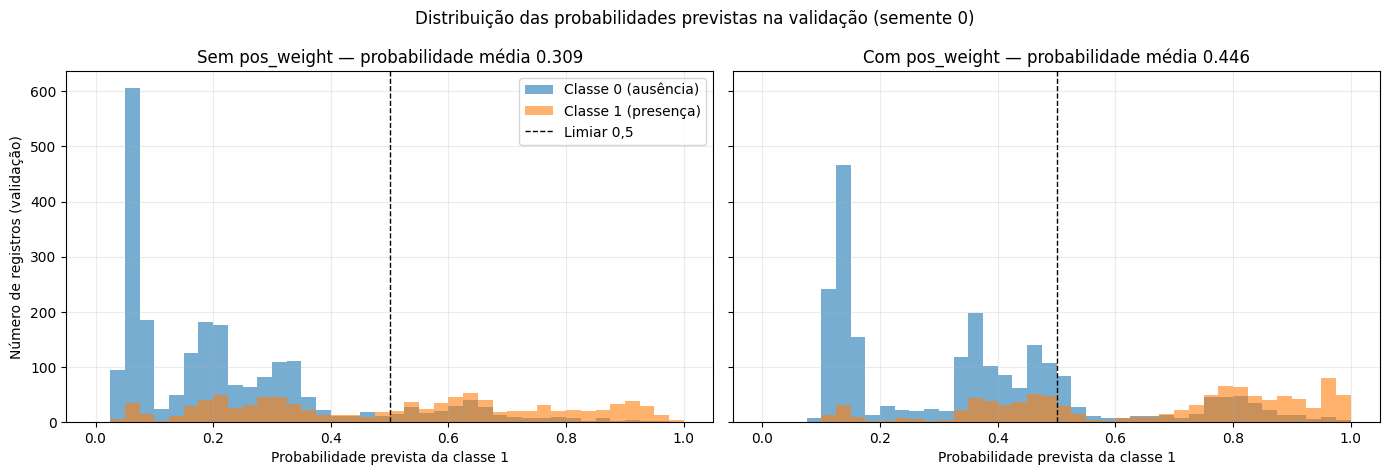

In [11]:
# Distribuição das probabilidades previstas na validação (semente 0)
import matplotlib.pyplot as plt

fig, eixos = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
bins = np.linspace(0, 1, 41)
for eixo, (titulo, prob) in zip(eixos, [("Sem pos_weight", prob_base), ("Com pos_weight", prob_pw)]):
    p = prob[0]["validacao"]
    eixo.hist(p[y_val == 0], bins=bins, alpha=0.6, label="Classe 0 (ausência)")
    eixo.hist(p[y_val == 1], bins=bins, alpha=0.6, label="Classe 1 (presença)")
    eixo.axvline(0.5, color="black", linestyle="--", linewidth=1, label="Limiar 0,5")
    eixo.set_title(f"{titulo} — probabilidade média {p.mean():.3f}")
    eixo.set_xlabel("Probabilidade prevista da classe 1")
    eixo.grid(alpha=0.25)
eixos[0].set_ylabel("Número de registros (validação)")
eixos[0].legend()
fig.suptitle("Distribuição das probabilidades previstas na validação (semente 0)")
fig.tight_layout()
fig.savefig(pasta_figuras / "classificacao_pos_weight_probabilidades.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

## 5. Curvas de aprendizado

As curvas mostram a perda por época no ajuste e na validação, para as cinco sementes, com e sem `pos_weight`. O marcador indica a época do melhor estado restaurado pelo *early stopping*. Como explicado na Seção 4, os dois painéis usam perdas em escalas diferentes e não devem ser comparados pelo valor absoluto.

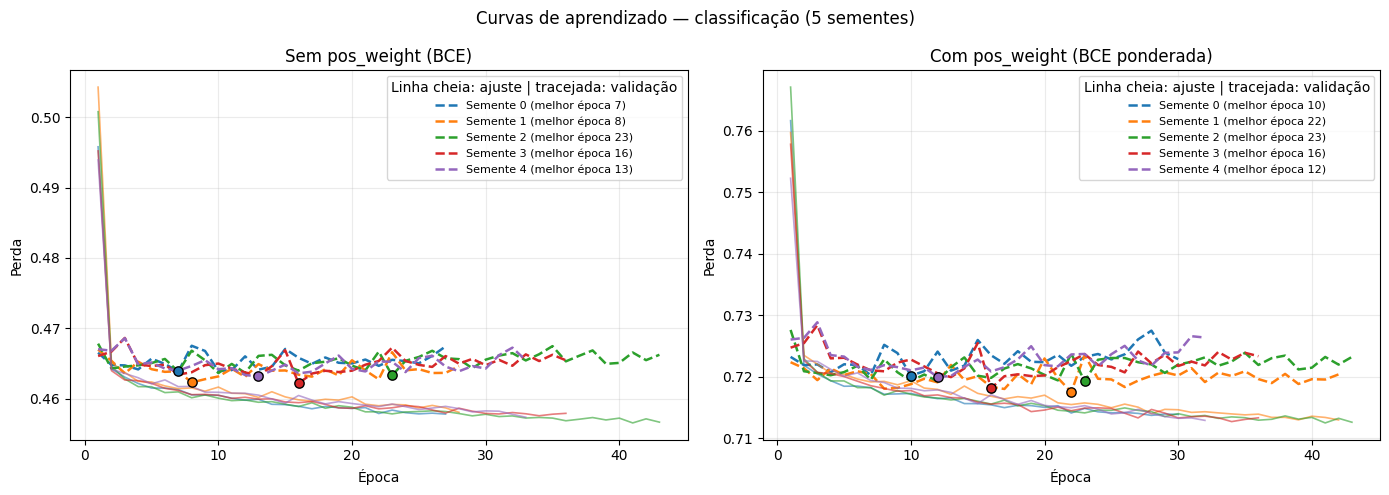

In [12]:
cores = plt.cm.tab10.colors
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))

for eixo, (titulo, hist, tabela) in zip(
    eixos, [("Sem pos_weight (BCE)", hist_base, tabela_base),
            ("Com pos_weight (BCE ponderada)", hist_pw, tabela_pw)]):
    for i, semente in enumerate(treino.SEMENTES):
        h = hist[semente]
        epocas = np.arange(1, len(h["val"]) + 1)
        melhor = int(tabela.loc[i, "epoca_melhor"])
        eixo.plot(epocas, h["treino"], color=cores[i], linewidth=1.2, alpha=0.6)
        eixo.plot(epocas, h["val"], color=cores[i], linewidth=1.8, linestyle="--",
                  label=f"Semente {semente} (melhor época {melhor})")
        eixo.scatter(melhor, h["val"][melhor - 1], color=cores[i], s=45, zorder=3, edgecolor="black")
    eixo.set_title(titulo)
    eixo.set_xlabel("Época")
    eixo.set_ylabel("Perda")
    eixo.grid(alpha=0.25)
    eixo.legend(title="Linha cheia: ajuste | tracejada: validação", fontsize=8)

fig.suptitle("Curvas de aprendizado — classificação (5 sementes)")
fig.tight_layout()
fig.savefig(pasta_figuras / "classificacao_baseline_curvas.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

## 6. Curvas ROC e Precision–Recall na validação

As curvas são calculadas a partir das probabilidades (sigmoide do logit) da semente cuja AP de validação é a mediana das cinco, nas duas configurações. A linha de referência da curva Precision–Recall é a prevalência da classe positiva na validação: é a Precision de um classificador que não separa as classes.

Semente mediana (AP de validação): sem pos_weight = 3 | com pos_weight = 0


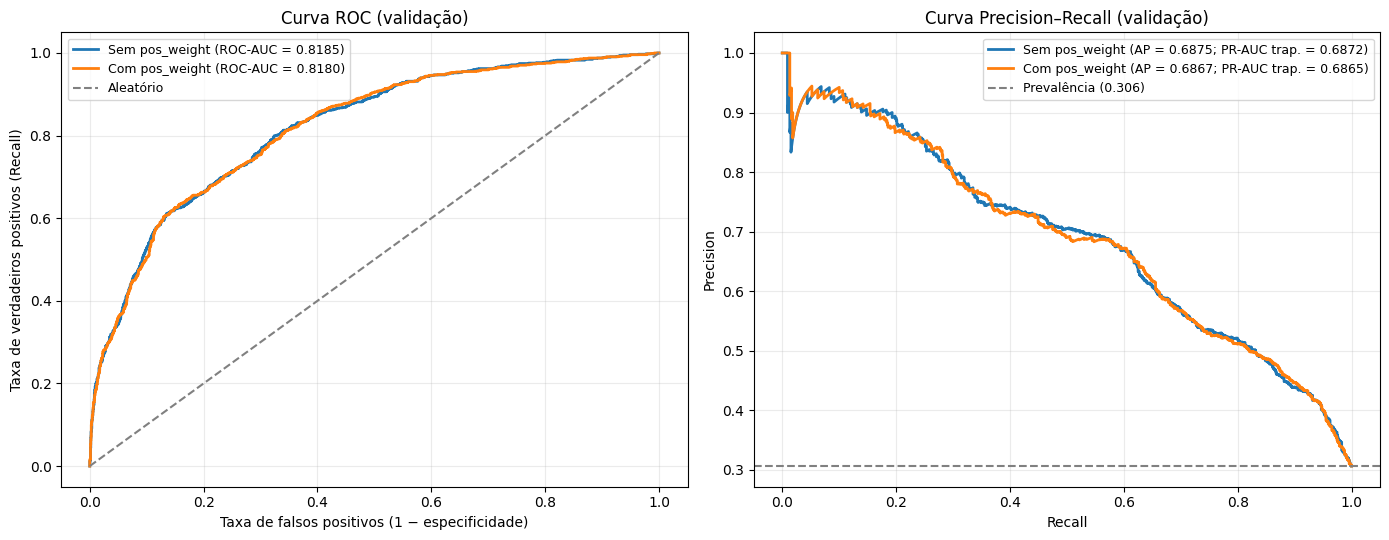

In [13]:
from sklearn.metrics import roc_curve, precision_recall_curve

def semente_mediana(tabela, coluna):
    ordem = tabela.sort_values(coluna).reset_index(drop=True)
    return int(ordem.loc[len(ordem) // 2, "semente"])

sem_base = semente_mediana(tabela_base, "Average_Precision_validacao")
sem_pw = semente_mediana(tabela_pw, "Average_Precision_validacao")
print("Semente mediana (AP de validação): sem pos_weight =", sem_base, "| com pos_weight =", sem_pw)

fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5))
for rotulo, prob, semente, cor in [("Sem pos_weight", prob_base, sem_base, cores[0]),
                                   ("Com pos_weight", prob_pw, sem_pw, cores[1])]:
    p = prob[semente]["validacao"]
    m = metricas.calcular_metricas_classificacao(y_val, p)
    fpr, tpr, _ = roc_curve(y_val, p)
    precisao, recall, _ = precision_recall_curve(y_val, p)
    eixos[0].plot(fpr, tpr, color=cor, linewidth=2, label=f"{rotulo} (ROC-AUC = {m['ROC-AUC']:.4f})")
    eixos[1].plot(recall, precisao, color=cor, linewidth=2,
                  label=f"{rotulo} (AP = {m['Average_Precision']:.4f}; PR-AUC trap. = {m['PR-AUC']:.4f})")

eixos[0].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Aleatório")
eixos[0].set_xlabel("Taxa de falsos positivos (1 − especificidade)")
eixos[0].set_ylabel("Taxa de verdadeiros positivos (Recall)")
eixos[0].set_title("Curva ROC (validação)")
eixos[1].axhline(y_val.mean(), color="gray", linestyle="--", label=f"Prevalência ({y_val.mean():.3f})")
eixos[1].set_xlabel("Recall")
eixos[1].set_ylabel("Precision")
eixos[1].set_title("Curva Precision–Recall (validação)")
for eixo in eixos:
    eixo.legend(fontsize=9)
    eixo.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(pasta_figuras / "classificacao_baseline_roc_pr_validacao.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

## 7. Efeito do limiar de decisão na validação

A rede produz probabilidades; a classe prevista depende do limiar $t$: o registro é classificado como positivo quando $\hat{p} \geq t$. Diminuir o limiar classifica mais registros como positivos, o que aumenta o Recall (menos falsos negativos) e tende a reduzir a Precision (mais falsos positivos). Aumentar o limiar faz o contrário.

A análise abaixo varre os limiares de 0,05 a 0,95 na **validação**, para as duas configurações (semente mediana). Ela mostra o comportamento do compromisso entre Precision e Recall e indica, como referência, o limiar que maximiza o F1-score em cada caso. **O limiar definitivo será escolhido na validação, com o modelo final, no Notebook 06**; o teste não participa dessa escolha.

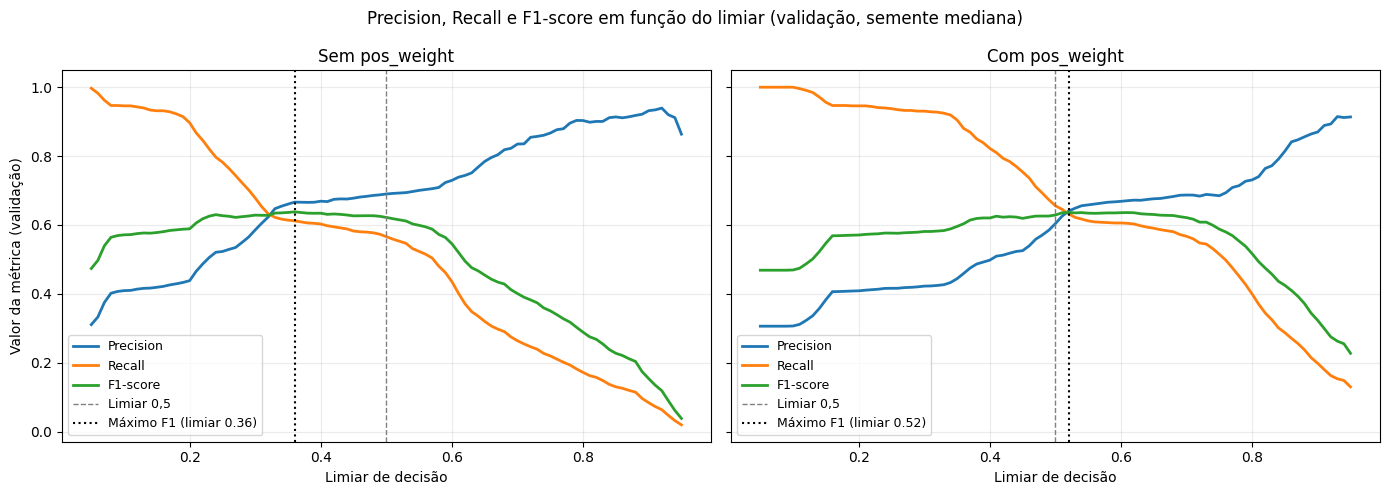

Configuração,Ponto,limiar,Precision,Recall,F1-score,% previstos positivos
Sem pos_weight,"Limiar 0,5",0.5000,0.6899,0.5659,0.6218,25.0937
Sem pos_weight,Máximo F1 (referência),0.3600,0.6663,0.6118,0.6379,28.0938
Com pos_weight,"Limiar 0,5",0.5000,0.6040,0.6558,0.6288,33.2188
Com pos_weight,Máximo F1 (referência),0.5200,0.6401,0.6323,0.6362,30.2188


In [14]:
from sklearn.metrics import f1_score, precision_score, recall_score

limiares = np.round(np.arange(0.05, 0.951, 0.01), 2)

def varrer_limiares(y, p):
    linhas = []
    for t in limiares:
        pred = (p >= t).astype(int)
        linhas.append({
            "limiar": t,
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F1-score": f1_score(y, pred, zero_division=0),
            "% previstos positivos": 100 * pred.mean(),
        })
    return pd.DataFrame(linhas)

varreduras = {
    "Sem pos_weight": varrer_limiares(y_val, prob_base[sem_base]["validacao"]),
    "Com pos_weight": varrer_limiares(y_val, prob_pw[sem_pw]["validacao"]),
}

fig, eixos = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
resumo_limiar = []
for eixo, (rotulo, v) in zip(eixos, varreduras.items()):
    for metrica, estilo in [("Precision", "-"), ("Recall", "-"), ("F1-score", "-")]:
        eixo.plot(v["limiar"], v[metrica], estilo, linewidth=2, label=metrica)
    melhor = v.loc[v["F1-score"].idxmax()]
    em_05 = v.loc[np.isclose(v["limiar"], 0.5)].iloc[0]
    eixo.axvline(0.5, color="gray", linestyle="--", linewidth=1, label="Limiar 0,5")
    eixo.axvline(melhor["limiar"], color="black", linestyle=":", linewidth=1.5,
                 label=f"Máximo F1 (limiar {melhor['limiar']:.2f})")
    eixo.set_title(rotulo)
    eixo.set_xlabel("Limiar de decisão")
    eixo.grid(alpha=0.25)
    eixo.legend(fontsize=9)
    for nome, linha in [("Limiar 0,5", em_05), ("Máximo F1 (referência)", melhor)]:
        resumo_limiar.append({"Configuração": rotulo, "Ponto": nome, **linha.to_dict()})
eixos[0].set_ylabel("Valor da métrica (validação)")
fig.suptitle("Precision, Recall e F1-score em função do limiar (validação, semente mediana)")
fig.tight_layout()
fig.savefig(pasta_figuras / "classificacao_limiar_validacao.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

tabela_limiar = pd.DataFrame(resumo_limiar)
display(tabela_limiar.style.format(precision=4).hide(axis="index"))

In [15]:
# Matrizes de confusão na validação: limiar 0,5 e limiar de máximo F1 (referência)
from sklearn.metrics import confusion_matrix

linhas = []
for rotulo, prob, semente in [("Sem pos_weight", prob_base, sem_base), ("Com pos_weight", prob_pw, sem_pw)]:
    p = prob[semente]["validacao"]
    v = varreduras[rotulo]
    for nome, t in [("0,5", 0.5), ("máximo F1", float(v.loc[v["F1-score"].idxmax(), "limiar"]))]:
        tn, fp, fn, tp = confusion_matrix(y_val, (p >= t).astype(int), labels=[0, 1]).ravel()
        linhas.append({"Configuração": rotulo, "Limiar": f"{nome} ({t:.2f})",
                       "VN": tn, "FP": fp, "FN": fn, "VP": tp})
tabela_confusao = pd.DataFrame(linhas)
print("MATRIZES DE CONFUSÃO NA VALIDAÇÃO (VN, FP, FN, VP)")
display(tabela_confusao.style.hide(axis="index"))

MATRIZES DE CONFUSÃO NA VALIDAÇÃO (VN, FP, FN, VP)


Configuração,Limiar,VN,FP,FN,VP
Sem pos_weight,"0,5 (0.50)",1972,249,425,554
Sem pos_weight,máximo F1 (0.36),1921,300,380,599
Com pos_weight,"0,5 (0.50)",1800,421,337,642
Com pos_weight,máximo F1 (0.52),1873,348,360,619


A comparação entre os pontos de F1-score máximo das duas configurações indica se, neste experimento, o `pos_weight` alterou a capacidade de separação das classes ou principalmente a posição do limiar adequado. As duas estratégias não são equivalentes em geral: o peso modifica a função de perda e, portanto, o treinamento e potencialmente a ordenação aprendida, enquanto o limiar apenas muda a decisão aplicada a probabilidades já produzidas.

## 8. Generalização do baseline

O gap é calculado como **métrica no ajuste − métrica na validação**. Todas as métricas comparadas aqui são de qualidade (maior é melhor), então **gap positivo significa desempenho pior na validação**.

As métricas independentes do limiar (ROC-AUC e AP) são as mais adequadas para essa leitura, porque não misturam a qualidade do modelo com a escolha do limiar. O F1-score no limiar 0,5 também é apresentado.

**Referência de escala.** Ajuste e validação são amostras diferentes, e a dificuldade de separar as classes não é exatamente a mesma nas duas. Por isso, mesmo um modelo que quase não consegue sobreajustar apresenta gap. A referência ingênua não serve de escala aqui, porque seu gap nas métricas de ordenação é zero por construção (ROC-AUC = 0,5 nos dois conjuntos). Usa-se então o gap da **regressão logística** (Seção 3.1): ele indica a diferença esperada entre os conjuntos para um modelo de baixa capacidade.

**Leitura.** Como no Notebook 03, a leitura é **heurística**, e não um teste estatístico. Os gaps de cada semente são apresentados ao lado do gap da regressão logística e da variação entre sementes. Um gap positivo, consistente nas cinco sementes e claramente **maior** que o da regressão logística, seria um sinal compatível com sobreajuste. Um gap da mesma ordem do gap da regressão logística, ou com sinal variável, não sustenta essa conclusão. Note que a consistência do sinal entre sementes, sozinha, não basta: se a diferença vem da composição das amostras, ela aparece em todas as sementes.

In [16]:
tabela_gap = pd.DataFrame({"semente": tabela_base["semente"]})
for m in ["ROC-AUC", "Average_Precision", "PR-AUC", "F1-score"]:
    tabela_gap[f"Gap {m} (ajuste − validação)"] = tabela_base[f"{m}_ajuste"] - tabela_base[f"{m}_validacao"]
display(tabela_gap.style.format(precision=4).hide(axis="index"))

resumo_gap = pd.DataFrame({
    "Gap médio": tabela_gap.drop(columns="semente").mean(),
    "Desvio do gap (ddof=1)": tabela_gap.drop(columns="semente").std(ddof=1),
    "Sementes com gap positivo": (tabela_gap.drop(columns="semente") > 0).sum(),
})
resumo_gap["Desvio da métrica de validação entre sementes (ddof=1)"] = [
    tabela_base[f"{m}_validacao"].std(ddof=1) for m in ["ROC-AUC", "Average_Precision", "PR-AUC", "F1-score"]
]
resumo_gap["Gap da regressão logística (referência)"] = [
    metricas_logistica["ajuste"][m] - metricas_logistica["validacao"][m]
    for m in ["ROC-AUC", "Average_Precision", "PR-AUC", "F1-score"]
]
display(resumo_gap.style.format({"Gap médio": "{:+.4f}", "Desvio do gap (ddof=1)": "{:.4f}",
                                 "Gap da regressão logística (referência)": "{:+.4f}",
                                 "Desvio da métrica de validação entre sementes (ddof=1)": "{:.4f}"}))
print("Leitura heurística, não um teste estatístico (ver o texto acima).")

semente,Gap ROC-AUC (ajuste − validação),Gap Average_Precision (ajuste − validação),Gap PR-AUC (ajuste − validação),Gap F1-score (ajuste − validação)
0,0.0025,0.0130,0.0133,0.0153
1,0.0024,0.0129,0.0131,0.0054
2,0.0050,0.0218,0.0221,0.0216
3,0.0030,0.0160,0.0163,0.0130
4,0.0013,0.0116,0.0118,0.0151


,Gap médio,Desvio do gap (ddof=1),Sementes com gap positivo,Desvio da métrica de validação entre sementes (ddof=1),Gap da regressão logística (referência)
Gap ROC-AUC (ajuste − validação),+0.0028,0.0014,5,0.0005,+0.0035
Gap Average_Precision (ajuste − validação),+0.0151,0.0041,5,0.0013,+0.0104
Gap PR-AUC (ajuste − validação),+0.0153,0.0041,5,0.0013,+0.0106
Gap F1-score (ajuste − validação),+0.0141,0.0058,5,0.0080,-0.0000


Leitura heurística, não um teste estatístico (ver o texto acima).


## 9. Exportação dos resultados

As tabelas são salvas em `reports/tables`, sem arredondamento. As curvas de perda de cada semente, nas duas configurações, já foram salvas em `logs/curvas/`.

In [17]:
tabelas = {
    "classificacao_baseline_sementes.csv": tabela_base,
    "classificacao_baseline_resumo.csv": resumo_base.rename_axis("Indicador").reset_index(),
    "classificacao_pos_weight_sementes.csv": tabela_pw,
    "classificacao_pos_weight_resumo.csv": resumo_pw.rename_axis("Indicador").reset_index(),
    "classificacao_pos_weight_comparacao.csv": comparacao_pw.rename_axis("Métrica").reset_index(),
    "classificacao_referencias_ingenuas.csv": tabela_referencias.rename_axis("Modelo").reset_index(),
    "classificacao_limiar_validacao.csv": pd.concat(
        [v.assign(Configuração=k) for k, v in varreduras.items()], ignore_index=True),
    "classificacao_limiar_resumo.csv": tabela_limiar,
    "classificacao_confusao_validacao.csv": tabela_confusao,
    "classificacao_baseline_gap.csv": tabela_gap,
    "classificacao_baseline_gap_resumo.csv": resumo_gap.rename_axis("Indicador").reset_index(),
}
for nome, tabela in tabelas.items():
    tabela.to_csv(pasta_tabelas / nome, index=False, encoding="utf-8-sig", float_format="%.16g")
    print("Salvo:", (pasta_tabelas / nome).relative_to(PROJETO))

print("\nFiguras:")
for nome in ["classificacao_pos_weight_probabilidades.png", "classificacao_baseline_curvas.png",
             "classificacao_baseline_roc_pr_validacao.png", "classificacao_limiar_validacao.png"]:
    assert (pasta_figuras / nome).is_file()
    print("Salvo:", (pasta_figuras / nome).relative_to(PROJETO))

Salvo: reports/tables/classificacao_baseline_sementes.csv
Salvo: reports/tables/classificacao_baseline_resumo.csv
Salvo: reports/tables/classificacao_pos_weight_sementes.csv
Salvo: reports/tables/classificacao_pos_weight_resumo.csv
Salvo: reports/tables/classificacao_pos_weight_comparacao.csv
Salvo: reports/tables/classificacao_referencias_ingenuas.csv
Salvo: reports/tables/classificacao_limiar_validacao.csv
Salvo: reports/tables/classificacao_limiar_resumo.csv
Salvo: reports/tables/classificacao_confusao_validacao.csv
Salvo: reports/tables/classificacao_baseline_gap.csv
Salvo: reports/tables/classificacao_baseline_gap_resumo.csv

Figuras:
Salvo: reports/figures/classificacao_pos_weight_probabilidades.png
Salvo: reports/figures/classificacao_baseline_curvas.png
Salvo: reports/figures/classificacao_baseline_roc_pr_validacao.png
Salvo: reports/figures/classificacao_limiar_validacao.png


## 10. Síntese

**Aprendizado.** A rede separa as classes de forma consistente: ROC-AUC de validação próxima de 0,82 e Average Precision próxima de 0,69, bem acima das referências que não ordenam os registros (ROC-AUC de 0,5 e AP igual à prevalência, cerca de 0,31). Em relação à regressão logística, as cinco sementes obtêm ROC-AUC e AP ligeiramente superiores. Esse ganho é pequeno e indica, de forma preliminar, que as não linearidades acrescentam alguma informação; ele não é tratado como conclusivo, porque a incerteza associada à própria amostra de validação não foi estimada aqui. Os valores exatos estão nas tabelas da Seção 3.

**Accuracy e limiar.** O classificador que prevê sempre a classe majoritária já atinge Accuracy próxima de 0,69 sem identificar nenhum caso positivo, o que mostra que a Accuracy, isoladamente, não descreve a utilidade do modelo neste problema. No limiar padrão de 0,5, o F1-score da rede fica abaixo do da regressão logística, embora ROC-AUC e AP sejam superiores. Isso mostra que o desempenho no limiar padrão não resume a capacidade de ordenação dos modelos; por isso, as configurações são comparadas pela AP de validação, e o F1-score é considerado após a escolha do limiar.

**Efeito do `pos_weight`.** Neste baseline, o `pos_weight` alterou pouco as métricas de ordenação (ROC-AUC, AP e PR-AUC trapezoidal), com diferenças dentro da variação entre sementes, mas deslocou as probabilidades e o ponto de operação no limiar de 0,5: o Recall aumentou e a Precision diminuiu, com menos falsos negativos e mais falsos positivos. Sem o peso, a média das probabilidades previstas fica próxima da prevalência observada, o que indica alinhamento médio agregado, mas não basta, isoladamente, para demonstrar calibração. Com o peso, a probabilidade média se afasta da prevalência e o Log Loss e o Brier Score pioram, indicando pior qualidade probabilística agregada neste experimento. Os F1-scores máximos das duas configurações foram semelhantes, em limiares diferentes. Isso sugere efeitos semelhantes sobre o compromisso entre Precision e Recall neste experimento, sem implicar equivalência geral entre ponderar a perda e ajustar o limiar. Esses pontos foram localizados na própria validação e servem apenas como referência comparativa.

**Generalização.** Na ROC-AUC, o gap entre ajuste e validação é da mesma ordem do gap da regressão logística. Na AP, o gap da rede é ligeiramente maior que o da regressão logística em todas as sementes, o que é compatível com a variância um pouco maior de um modelo com mais parâmetros. Como o desempenho de validação da rede permanece superior ao do modelo linear e o *early stopping* interrompe o treinamento cedo, não há evidência de sobreajuste que prejudique a validação. A relação entre capacidade e gap é examinada no estudo de neurônios e camadas.

**Decisão para o estudo de hiperparâmetros.** O estudo principal será conduzido sem `pos_weight`. No experimento preliminar, seu uso não trouxe ganho relevante de AP ou PR-AUC trapezoidal em relação à variação entre sementes, mas elevou as probabilidades previstas e piorou o Log Loss e o Brier Score. Por isso, para este estudo, prioriza-se o modelo sem peso, e as configurações são selecionadas pela AP de validação. O compromisso entre Precision e Recall será tratado pelo limiar de decisão, escolhido separadamente na validação, sem consultar o teste. Essa escolha é uma decisão metodológica baseada nos resultados preliminares; não implica que o `pos_weight` seja sempre irrelevante nem que sua inclusão produziria necessariamente as mesmas conclusões. A pequena distância entre a rede e o modelo linear reforça a hipótese, já levantada na regressão, de que o desempenho pode estar limitado pela informação disponível nas seis features.